# 03 — Nettoyage et prétraitement (Partie 3 du TP)

**Objectif** : exploiter les constats de l'EDA (notebook 02) pour produire un dataset propre, en justifiant chaque décision et l'ordre des traitements. Seules les méthodes des cours 03–05 sont utilisées.

| # | Constat de la prof | Vérification dans ce notebook |
|---|---|---|
| 1 | Valeurs manquantes à la frontière nord | Étape 3 |
| 2 | Features à très faible variabilité | Étape 5 |
| 3 | Asymétrie et outliers (histogrammes, boxplots) | Étape 4 |
| 4 | Incohérences des moyennes mensuelles 2022–2024 | Étape 2 |
| 5 | Fortes corrélations (bonne formule) | Étape 6 |

## Ordre d'application (justifié par les résultats obtenus plus bas)
1. **Intégrité** — dates, doublons, version des données : tout le reste suppose une série temporelle complète et ordonnée.
2. **Incohérence 2022-09 → 2024-02** — elle divise par ≈ 2 les 7 variables accumulées : elle fausse moyennes, variances, outliers et corrélations ; elle doit donc être corrigée **avant** tout calcul statistique.
3. **Valeurs manquantes (frontière nord)** — définit le domaine spatial des échantillons.
4. **Outliers et asymétrie** — décidés sur les données corrigées (sinon l'artefact crée de faux extrêmes).
5. **Faible variabilité** — la variance après normalisation Min-Max est écrasée par les queues lourdes ; on la juge donc **après** transformation, sinon slhf, e et tp seraient déclarées pauvres à tort.
6. **Corrélations / redondance** — sur données corrigées ; Spearman étant invariant aux transformations monotones (racine carrée), l'étape 4 ne change pas ce résultat.
7. **Dataset final** — cible t2m(t+1), mois, année. **Pas de scaling ni de découpage ici** : ils seront ajustés sur le train seulement (étape 2 du projet) pour éviter toute fuite d'information.

Les données brutes ne sont jamais modifiées : `ARR_RAW` reste intact, tous les traitements portent sur la copie `ARR`.

In [1]:
%matplotlib inline
from pathlib import Path
import sys, warnings
import numpy as np, pandas as pd, xarray as xr
import matplotlib.pyplot as plt, seaborn as sns
from scipy import stats
from sklearn.linear_model import LinearRegression
from IPython.display import display

warnings.filterwarnings("ignore", category=RuntimeWarning)
plt.style.use("seaborn-v0_8-whitegrid"); pd.set_option("display.width", 220); pd.set_option("display.max_columns", 40)

_here = Path.cwd().resolve()
PROJECT_ROOT = next((p for p in [_here, *_here.parents]
                     if (p/"data"/"processed"/"era5_algeria_masked_2x2_v2.nc").exists()), None)
if PROJECT_ROOT is None:
    raise FileNotFoundError("era5_algeria_masked_2x2_v2.nc introuvable : exécutez d'abord le notebook 01.")
sys.path.insert(0, str(PROJECT_ROOT/"src"))
from climate_utils import make_algeria_mask
OUT = PROJECT_ROOT/"data"/"processed"
FIG = PROJECT_ROOT/"reports"/"figures"; FIG.mkdir(parents=True, exist_ok=True)   # figures réutilisées dans le rapport

ds = xr.open_dataset(OUT/"era5_algeria_masked_2x2_v2.nc")
ds_raw = xr.open_dataset(PROJECT_ROOT/"data"/"raw"/"era5_algeria_raw.nc")
print("Grille réduite :", dict(ds.sizes), "| grille brute :", dict(ds_raw.sizes))

Grille réduite : {'valid_time': 141, 'latitude': 95, 'longitude': 105} | grille brute : {'valid_time': 141, 'latitude': 191, 'longitude': 211}


## Étape 1 — Chargement, unités et intégrité

In [2]:
BASE = ["d2m","t2m","slhf","ssr","str","sshf","ro","e","u10","v10","sp","tp"]
ACCUM = ["slhf","ssr","str","sshf","ro","e","tp"]        # variables accumulées (flux, rayonnements, eau)
INST  = ["d2m","t2m","u10","v10","sp"]                    # variables instantanées
UNITS = {"d2m":"°C","t2m":"°C","slhf":"W/m²","ssr":"W/m²","str":"W/m²","sshf":"W/m²",
         "ro":"mm/j","e":"mm/j","tp":"mm/j","u10":"m/s","v10":"m/s","sp":"hPa"}

conv = xr.Dataset(coords=ds.coords)
for v in ["d2m","t2m"]:               conv[v] = ds[v] - 273.15     # K -> °C
for v in ["slhf","ssr","str","sshf"]: conv[v] = ds[v] / 86400.0    # J/m² par jour -> W/m²
for v in ["ro","e","tp"]:             conv[v] = ds[v] * 1000.0     # m/jour -> mm/jour
conv["sp"] = ds["sp"] / 100.0                                      # Pa -> hPa
conv["u10"], conv["v10"] = ds["u10"], ds["v10"]

valid_cells = conv["t2m"].notnull().any("valid_time"); vm = valid_cells.values
times = pd.DatetimeIndex(conv.valid_time.values)
T, N = len(times), int(vm.sum())
months, years = times.month.values, times.year.values
ilat, ilon = np.where(vm)
LAT, LON = conv.latitude.values[ilat], conv.longitude.values[ilon]

ARR_RAW = {v: conv[v].values[:, vm].astype("float64") for v in BASE}   # version BRUTE, jamais modifiée
ARR = {v: a.copy() for v, a in ARR_RAW.items()}                         # copie de travail (T mois × N cellules)

# Intégrité
print(f"{T} mois × {N:,} cellules = {T*N:,} échantillons | {times.min():%Y-%m} → {times.max():%Y-%m}")
print("Dates triées :", times.is_monotonic_increasing, "| doublons :", int(times.duplicated().sum()),
      "| mois consécutifs :", bool((np.diff(times.year*12 + times.month) == 1).all()))
expver = pd.Series(ds["expver"].values, index=times.strftime("%Y-%m"))
print("Versions expver :", expver.value_counts().to_dict(), "| mois en version préliminaire (ERA5T, 0005) :", expver[expver == "0005"].index.tolist())
print("NaN dans les cellules du domaine :", sum(int(np.isnan(a).sum()) for a in ARR.values()))

141 mois × 5,424 cellules = 764,784 échantillons | 2015-01 → 2026-09
Dates triées : True | doublons : 0 | mois consécutifs : True
Versions expver : {'0001': 139, '0005': 2} | mois en version préliminaire (ERA5T, 0005) : ['2026-08', '2026-09']
NaN dans les cellules du domaine : 0


**Lecture** : série complète et régulière, aucun doublon, aucun NaN dans les 5 424 cellules. Les deux derniers mois sont en version préliminaire ERA5T (`expver = 0005`) : ils sont conservés mais marqués (`prelim_era5t`) car ils peuvent encore être révisés par l'ECMWF (critère *timeliness / believability* du cours 04).

## Étape 2 — Incohérence temporelle 2022-09 → 2024-02

**Pourquoi d'abord** : une période où des variables sont divisées par 2 fausse toutes les statistiques suivantes.

La période n'est pas reprise telle quelle de l'EDA : on la **redétecte** sur les rayonnements `ssr` et `str`, dont la variabilité interannuelle n'est que de quelques %. Pour les variables instantanées on raisonne en écarts-types et non en rapport, car un rapport n'a pas de sens pour une température en °C (échelle d'intervalle, cours 02).

In [3]:
wcos = np.cos(np.deg2rad(LAT))
def regional(a):                      # moyenne régionale pondérée par cos(lat) d'un tableau (T, N)
    return (a * wcos).sum(1) / wcos.sum()

REG_RAW = pd.DataFrame({v: regional(ARR_RAW[v]) for v in BASE}, index=times)
clim_reg = REG_RAW.groupby(times.month).transform("median")      # médiane du même mois calendaire

# 1) Détection de la période : ssr et str sont les flux les plus stables d'une année à l'autre
#    (variations interannuelles de quelques %), une chute de plus de 25 % n'a donc rien de climatique.
RATIO = REG_RAW[ACCUM] / clim_reg[ACCUM]
suspect = RATIO[["ssr", "str"]].median(axis=1) < 0.75
idx = np.where(suspect)[0]
print(f"Mois suspects : {suspect.sum()} | {times[idx[0]]:%Y-%m} → {times[idx[-1]]:%Y-%m} | consécutifs : {bool(np.all(np.diff(idx) == 1))}")
win = suspect.values; clean = ~win
ANOM_START, ANOM_END = times[idx[0]], times[idx[-1]]

# 2) Variables accumulées : rapport à la climatologie dans et hors de la période
display(pd.DataFrame({"rapport médian DANS la période": RATIO[win].median(),
                      "rapport médian HORS période": RATIO[clean].median()}).T.round(3))

# 3) Variables instantanées : écart à la climatologie en écarts-types (le rapport n'a pas de sens pour des °C)
clim_c = REG_RAW[clean].groupby(times[clean].month).median()
resid = REG_RAW - clim_c.loc[times.month].values
z_inst = (resid[INST][win].mean() / resid[INST][clean].std()).rename("écart moyen dans la période (écarts-types)")
display(z_inst.round(2).to_frame().T)

Mois suspects : 18 | 2022-09 → 2024-02 | consécutifs : True


,slhf,ssr,str,sshf,ro,e,tp
rapport médian DANS la période,0.431,0.537,0.494,0.494,0.284,0.431,0.415
rapport médian HORS période,1.023,1.001,1.003,1.006,1.039,1.023,1.061


,d2m,t2m,u10,v10,sp
écart moyen dans la période (écarts-types),-0.45,0.63,-0.1,0.12,0.13


**Lecture** : 18 mois consécutifs. Les **7 variables accumulées** (pas seulement ssr, str, sshf) tombent à 28–54 % de leur valeur habituelle ; les variables instantanées restent dans leur variabilité normale (< 1 écart-type). L'EDA ne détectait que ssr/str/sshf car slhf, e, tp et ro varient beaucoup naturellement d'une année à l'autre, ce qui masquait l'erreur.

Vérification cellule par cellule, signature de l'erreur et relation e / slhf :

,cellules évaluables,% cellules avec rapport < 0.75,rapport médian (cellules),P5,P95
variable,,,,,
slhf,5424,99.926,0.456,0.286,0.494
ssr,5424,100.000,0.536,0.508,0.557
str,5424,100.000,0.488,0.474,0.515
sshf,5424,99.982,0.477,0.413,0.589
ro,5424,99.594,0.115,0.000,0.382
e,5424,99.926,0.456,0.286,0.494
tp,5424,99.502,0.217,0.089,0.447


Rapport médian de ssr par bande de longitude : {Interval(-9, -4, closed='right'): 0.507, Interval(-4, 0, closed='right'): 0.519, Interval(0, 4, closed='right'): 0.533, Interval(4, 8, closed='right'): 0.545, Interval(8, 12, closed='right'): 0.554}
slhf / e : médiane 28.944 W/m² par mm/j | P1–P99 : 28.944 – 28.946 | valeur théorique Lv/86400 = 28.935


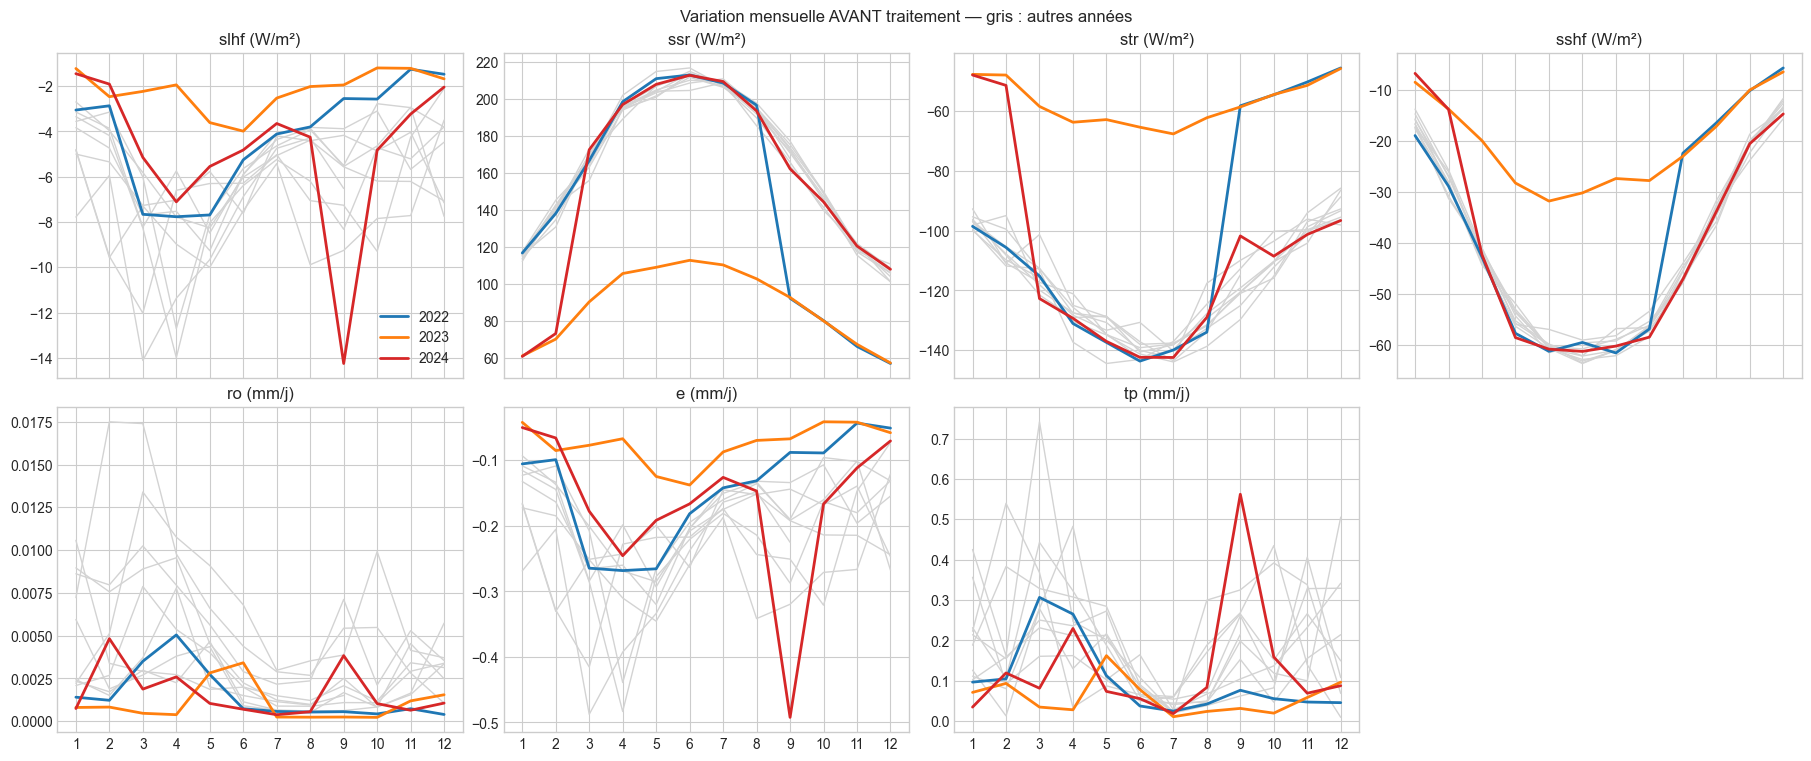

In [4]:
def clim_median(a, rows):
    """Médiane du même mois calendaire, cellule par cellule, calculée sur les lignes `rows` -> (12, N)."""
    return np.stack([np.median(a[rows & (months == m)], axis=0) for m in range(1, 13)])

rows = []
cell_ratio = {}
for v in ACCUM:
    cl = clim_median(ARR_RAW[v], clean)
    with np.errstate(divide="ignore", invalid="ignore"):
        r = np.nanmedian(ARR_RAW[v][win] / np.where(np.abs(cl[months[win]-1]) > 1e-6, cl[months[win]-1], np.nan), axis=0)
    cell_ratio[v] = r
    ok = ~np.isnan(r)
    rows.append({"variable": v, "cellules évaluables": int(ok.sum()),
                 "% cellules avec rapport < 0.75": 100*(r[ok] < 0.75).mean(),
                 "rapport médian (cellules)": np.median(r[ok]),
                 "P5": np.percentile(r[ok], 5), "P95": np.percentile(r[ok], 95)})
display(pd.DataFrame(rows).set_index("variable").round(3))

# signature de l'artefact : pour ssr, le rapport dépend de la longitude (heure UTC), pas du climat
bands = pd.cut(LON, [-9, -4, 0, 4, 8, 12])
print("Rapport médian de ssr par bande de longitude :", pd.Series(cell_ratio["ssr"]).groupby(bands, observed=True).median().round(3).to_dict())

# relation e / slhf : flux de chaleur latente = chaleur latente de vaporisation × évaporation
k = ARR_RAW["slhf"] / np.where(ARR_RAW["e"] != 0, ARR_RAW["e"], np.nan)          # (W/m²) / (mm/j)
print(f"slhf / e : médiane {np.nanmedian(k):.3f} W/m² par mm/j | P1–P99 : {np.nanpercentile(k, 1):.3f} – {np.nanpercentile(k, 99):.3f}"
      f" | valeur théorique Lv/86400 = {2.5e6/86400:.3f}")

# Graphique de variation mensuelle AVANT traitement
def monthly_plot(reg, title, fname):
    fig, axes = plt.subplots(2, 4, figsize=(18, 7.5), constrained_layout=True, sharex=True)
    for ax, v in zip(axes.flat, ACCUM):
        pv = reg[v].groupby([reg.index.year, reg.index.month]).mean().unstack(0)
        for y in pv.columns:
            if y not in (2022, 2023, 2024): ax.plot(pv.index, pv[y], color="lightgrey", lw=1)
        for y, c in [(2022, "tab:blue"), (2023, "tab:orange"), (2024, "tab:red")]:
            ax.plot(pv.index, pv[y], color=c, lw=2, label=str(y))
        ax.set_title(f"{v} ({UNITS[v]})"); ax.set_xticks(range(1, 13))
    axes.flat[0].legend(); axes.flat[-1].set_visible(False)
    fig.suptitle(title); fig.savefig(FIG/fname, dpi=110); plt.show()
monthly_plot(REG_RAW, "Variation mensuelle AVANT traitement — gris : autres années", "02_variation_mensuelle_avant.png")

**Origine de l'incohérence** :
- l'anomalie touche > 99,5 % des cellules pour les 7 variables : c'est un problème de produit, pas un phénomène local ;
- pour ssr, le rapport augmente régulièrement d'ouest en est (0,51 → 0,55) : c'est la signature d'une accumulation calculée sur une partie de la journée en temps UTC, pas d'un événement climatique ;
- c'est un **problème connu** d'ERA5-Land (annonce ECMWF : *Issue affecting ERA5-Land monthly averaged reanalysis for the period September 2022 to February 2024*, toutes les variables accumulées). La correction officielle consiste à re-télécharger ces mois avec le produit *monthly averaged reanalysis by hour of day* à 00:00. Ici on corrige sans re-téléchargement ;
- `e = slhf / 28,944` exactement (P1 = P99) : le flux de chaleur latente est l'évaporation multipliée par la chaleur latente de vaporisation (2,5·10⁶ J/kg ÷ 86 400 s). `e` n'apporte aucune information de plus que `slhf`.

**Traitement (cours 04)** : *delete value and handle as missing*, puis imputation. 12,8 % des mois sont concernés (> 5 %) : le cours recommande un **modèle prédictif** plutôt qu'une simple moyenne. On compare :
1. **Imputation « smart »** : moyenne ou médiane du même mois calendaire pour la même cellule (même « classe ») ;
2. **Régression linéaire** par cellule : anomalie de la variable expliquée par les anomalies de t2m, d2m, u10, v10, sp (non touchées par l'erreur).

Validation : on cache **deux blocs sains de 18 mois** de même structure (sept. → févr.) et on compare l'imputation aux vraies valeurs.

In [5]:
IMPUTE = ["slhf", "ssr", "str", "sshf", "ro", "tp"]       # e sera recalculée à partir de slhf (rapport constant)
K_E = float(np.nanmedian(ARR_RAW["slhf"] / np.where(ARR_RAW["e"] != 0, ARR_RAW["e"], np.nan)))
PRED = ["t2m", "d2m", "u10", "v10", "sp"]                 # variables non touchées par l'artefact
print(f"Mois à imputer : {win.sum()} / {T} = {100*win.mean():.1f} % (> 5 % → le cours recommande un modèle prédictif)")

def clim_mean(a, rows):
    return np.stack([a[rows & (months == m)].mean(axis=0) for m in range(1, 13)])

def impute(v, fit_rows, target_rows, method):
    """Impute la variable v sur target_rows à partir des mois fit_rows. Retourne un tableau (n_target, N)."""
    a = ARR_RAW[v]
    if method == "climatologie (moyenne)":
        return clim_mean(a, fit_rows)[months[target_rows]-1]
    if method == "climatologie (médiane)":
        return clim_median(a, fit_rows)[months[target_rows]-1]
    # Régression linéaire par cellule : anomalie(v) = b0 + Σ b_j × anomalie(prédicteur j)
    cv = clim_mean(a, fit_rows)
    Xa = np.stack([ARR_RAW[p] - clim_mean(ARR_RAW[p], fit_rows)[months-1] for p in PRED], axis=-1)   # (T, N, 5)
    ya = a - cv[months-1]
    out = np.empty((target_rows.sum(), N))
    Xf, Xt = Xa[fit_rows], Xa[target_rows]
    ones_f, ones_t = np.ones((fit_rows.sum(), 1)), np.ones((target_rows.sum(), 1))
    for j in range(N):
        coef = LinearRegression().fit(Xf[:, j], ya[fit_rows, j])
        out[:, j] = coef.predict(Xt[:, j])
    return cv[months[target_rows]-1] + out

def physical_bounds(v, x):           # signes imposés par la physique / la convention ERA5
    if v in ("ro", "tp", "ssr"): return np.maximum(x, 0)
    if v == "slhf": return np.minimum(x, 0)
    return x

# Validation : on cache des blocs de 18 mois SAINS ayant la même structure (septembre → février de l'année+2)
METHODS = ["climatologie (moyenne)", "climatologie (médiane)", "régression linéaire"]
pseudo = {"2016-09→2018-02": ("2016-09-01", "2018-02-01"), "2019-09→2021-02": ("2019-09-01", "2021-02-01")}
res = []
for name, (s, e_) in pseudo.items():
    hide = (times >= s) & (times <= e_)
    fit = clean & ~hide
    for v in IMPUTE:
        truth = ARR_RAW[v][hide]
        for mth in METHODS:
            p = physical_bounds(v, impute(v, fit, hide, mth))
            res.append({"bloc": name, "variable": v, "méthode": mth,
                        "MAE / écart-type": np.abs(p - truth).mean() / ARR_RAW[v][clean].std(),
                        "corr. régionale": np.corrcoef(regional(p), regional(truth))[0, 1]})
val = pd.DataFrame(res)
tab = val.groupby(["variable", "méthode"])[["MAE / écart-type", "corr. régionale"]].mean().unstack("méthode")
display(tab.round(3))
best_mae = val.groupby(["variable", "méthode"])["MAE / écart-type"].mean().unstack().idxmin(axis=1)
print("Méthode à MAE minimale :", best_mae.to_dict())

# Contrôle supplémentaire : l'imputation doit conserver les relations entre variables, pas seulement l'erreur moyenne.
# Exemple ro–tp (ruissellement produit par la pluie) : ρ entre ro imputé et tp imputé, comparé au ρ des vraies valeurs.
rows = []
for name, (s, e_) in pseudo.items():
    hide = (times >= s) & (times <= e_); fit = clean & ~hide
    tp_imp = physical_bounds("tp", impute("tp", fit, hide, "régression linéaire"))
    for mth in ["climatologie (médiane)", "régression linéaire"]:
        ro_imp = physical_bounds("ro", impute("ro", fit, hide, mth))
        rows.append({"méthode pour ro": mth, "ρ(ro, tp) imputés": stats.spearmanr(ro_imp.ravel()[::7], tp_imp.ravel()[::7])[0],
                     "ρ(ro, tp) vraies valeurs": stats.spearmanr(ARR_RAW["ro"][hide].ravel()[::7], ARR_RAW["tp"][hide].ravel()[::7])[0]})
display(pd.DataFrame(rows).groupby("méthode pour ro").mean().round(3))
best = pd.Series("régression linéaire", index=IMPUTE)
print("Méthode retenue pour les 6 variables : régression linéaire (MAE minimale ou quasi minimale ET relations conservées)")

Mois à imputer : 18 / 141 = 12.8 % (> 5 % → le cours recommande un modèle prédictif)


MAE / écart-type                                                   corr. régionale                                           
méthode  climatologie (moyenne) climatologie (médiane) régression linéaire climatologie (moyenne) climatologie (médiane) régression linéaire
variable                                                                                                                                    
ro                        0.074                  0.055               0.071                  0.263                  0.304               0.664
slhf                      0.210                  0.182               0.170                  0.437                  0.444               0.870
sshf                      0.124                  0.125               0.102                  0.997                  0.997               0.999
ssr                       0.090                  0.091               0.067                  0.996                  0.996               0.999
str                       0.201                  0.198               0.108                  0.964                  0.966               0.996
tp                        0.292                  0.255               0.230                  0.352                  0.336               0.810

Méthode à MAE minimale : {'ro': 'climatologie (médiane)', 'slhf': 'régression linéaire', 'sshf': 'régression linéaire', 'ssr': 'régression linéaire', 'str': 'régression linéaire', 'tp': 'régression linéaire'}


,"ρ(ro, tp) imputés","ρ(ro, tp) vraies valeurs"
méthode pour ro,,
climatologie (médiane),0.551,0.98
régression linéaire,0.925,0.98


Méthode retenue pour les 6 variables : régression linéaire (MAE minimale ou quasi minimale ET relations conservées)


**Choix** : la régression linéaire a l'erreur la plus faible pour 5 variables sur 6 et **conserve la variabilité interannuelle** (corrélation régionale 0,66–0,999) que la climatologie efface (0,26–0,44 pour ro, tp, slhf). Pour `ro`, la médiane a une MAE un peu plus faible car `ro ≈ 0` presque partout, mais elle **casse le lien physique pluie → ruissellement** (ρ(ro, tp) = 0,55 au lieu de 0,98) : un traitement ne doit pas introduire de nouvelle incohérence. On retient donc la régression pour les 6 variables ; `e` est recalculée à partir de `slhf`.

NaN créés : {'slhf': 97632, 'ssr': 97632, 'str': 97632, 'sshf': 97632, 'ro': 97632, 'e': 97632, 'tp': 97632}
NaN restants : 0
Contrôle e = slhf / K sur les mois sains : erreur relative P99 = 1.5e-04 (précision float32)


,slhf,ssr,str,sshf,ro,e,tp
rapport médian AVANT,0.431,0.537,0.494,0.494,0.284,0.431,0.415
rapport médian APRÈS,0.783,1.010,1.026,1.005,0.803,0.783,0.657


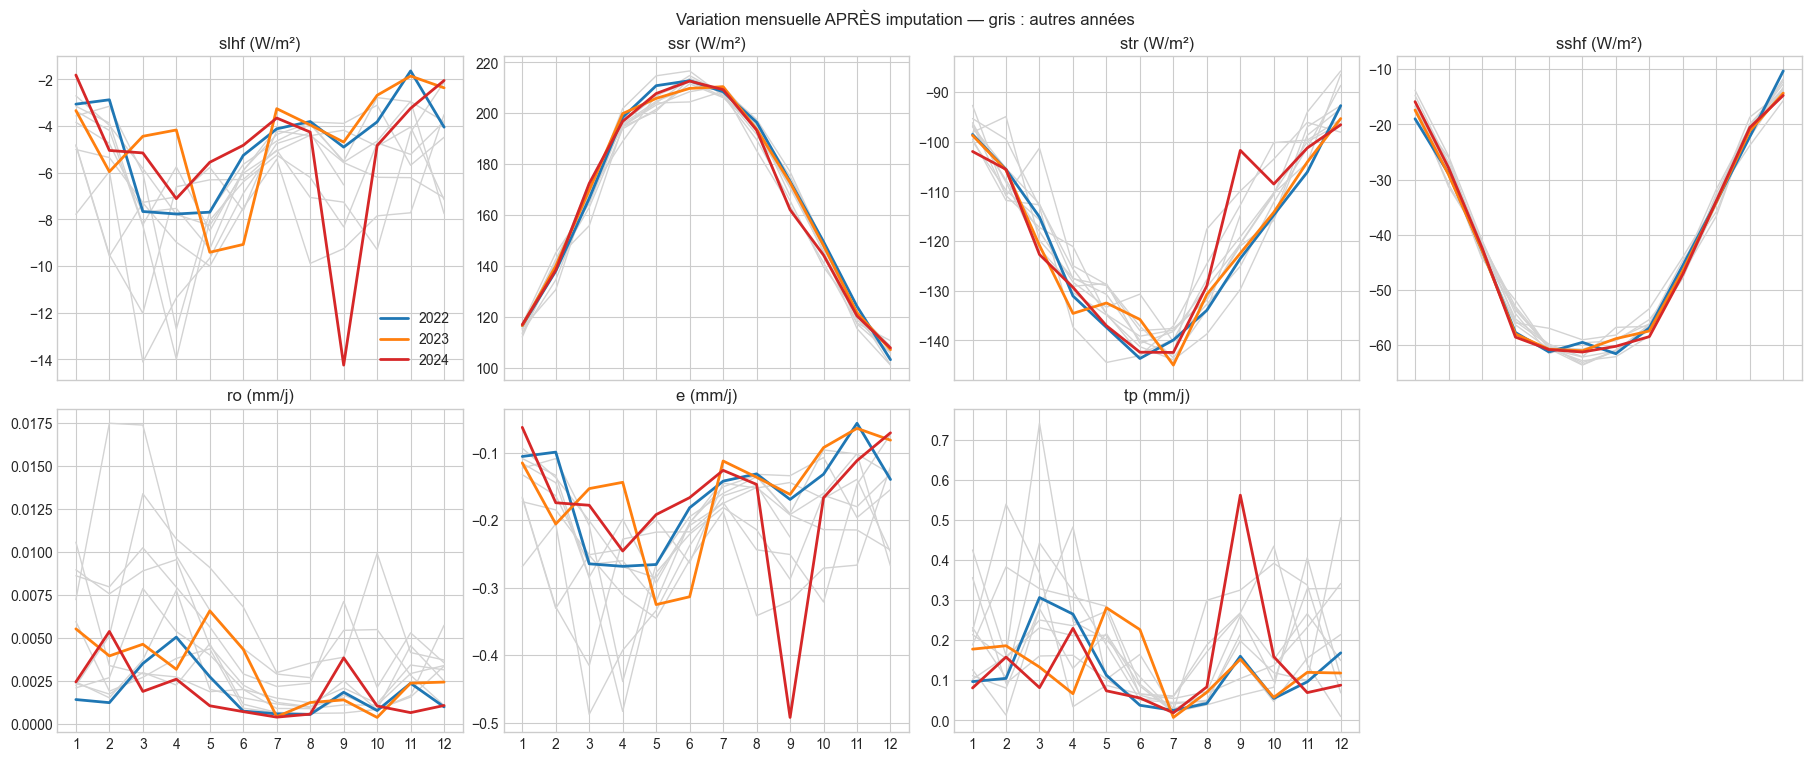

In [6]:
# (1) "Delete value and handle as missing" : les 18 mois erronés passent à NaN pour les 7 variables accumulées
for v in ACCUM:
    ARR[v][win] = np.nan
print("NaN créés :", {v: int(np.isnan(ARR[v]).sum()) for v in ACCUM})

# (2) Imputation par la méthode retenue en validation, ajustée sur TOUS les mois sains
for v in IMPUTE:
    ARR[v][win] = physical_bounds(v, impute(v, clean, win, best[v]))
ARR["e"][win] = ARR["slhf"][win] / K_E          # e = slhf / (Lv/86400) : relation exacte conservée
print("NaN restants :", sum(int(np.isnan(ARR[v]).sum()) for v in BASE))
rel = np.abs(ARR["slhf"] / K_E - ARR["e"]) / np.maximum(np.abs(ARR["e"]), 1e-3)
print(f"Contrôle e = slhf / K sur les mois sains : erreur relative P99 = {np.percentile(rel[clean], 99):.1e} (précision float32)")
IMPUTED = np.repeat(win, N)                      # drapeau par échantillon (cellule × mois)

REG = pd.DataFrame({v: regional(ARR[v]) for v in BASE}, index=times)
ratio_after = (REG[ACCUM] / REG[ACCUM][clean].groupby(times[clean].month).median().loc[times.month].values)
display(pd.DataFrame({"rapport médian AVANT": RATIO[win].median(), "rapport médian APRÈS": ratio_after[win].median()}).T.round(3))
monthly_plot(REG, "Variation mensuelle APRÈS imputation — gris : autres années", "03_variation_mensuelle_apres.png")

**Lecture** : les courbes 2022–2024 reviennent dans l'enveloppe des autres années. Les vrais extrêmes hors période (ex. septembre 2024, épisode de fortes pluies au Sahara) ne sont pas modifiés.

**Limite** : les 18 mois sont des **estimations**. Les rapports médians après correction (tp 0,66 ; slhf/e 0,78 ; ro 0,80) restent sous 1, ce qui est cohérent avec les anomalies sèches de t2m/d2m utilisées par le modèle, mais ne peut pas être vérifié sans les vraies valeurs. Le drapeau `imputed_accum` permet de tester la sensibilité des modèles à ces lignes.

## Étape 3 — Valeurs manquantes à la frontière nord

Le nombre de valeurs manquantes dépend de la méthode d'intersection avec la carte de l'Algérie. On examine leur origine et leur position avant de décider.

Méthode du notebook 01 (masque centre-de-cellule puis moyenne 2×2 ignorant les NaN) :
  grille brute : 21257 cellules dans le polygone, dont 12 sans aucune donnée (latitudes 35.3–37.0°N, toutes au-delà de 35°N : True)
  ces trous ont-ils des mois partiels ?  False → trous permanents = points de mer, ERA5-Land ne couvre que les terres
Méthode alternative (centre réduit dans le polygone + moyenne stricte) : 22 cellules NaN, toutes au nord : True (lat 35.0–37.0°N)

Répartition du nombre de sous-cellules valides (n_sub) : {np.int64(1): np.int64(74), np.int64(2): np.int64(78), np.int64(3): np.int64(73), np.int64(4): np.int64(5199)} → 4.15 % des cellules incomplètes
  dont côte nord (lat > 35.5°N) : 43 | frontières terrestres : 182
  |écart de t2m à la moyenne des voisines complètes| médian : incomplètes = 0.18 °C, complètes = 0.07 °C ; P95 : 1.23 vs 0.57 °C


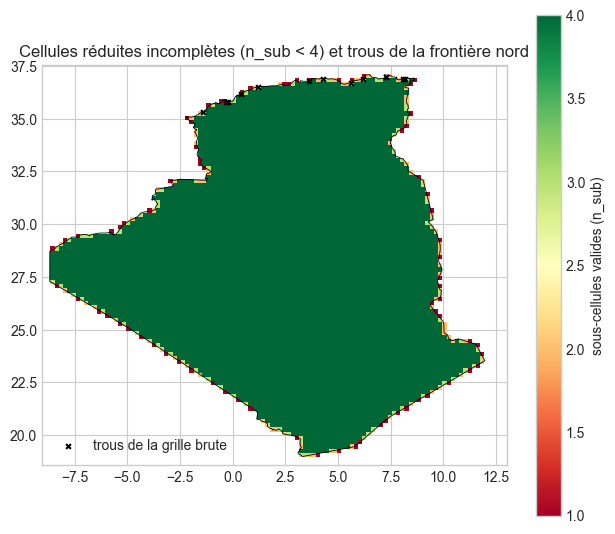

In [7]:
mask, algeria = make_algeria_mask(ds_raw, PROJECT_ROOT)
raw_ok = ds_raw["t2m"].notnull().all("valid_time")                    # cellule terrestre ERA5-Land
holes = mask & ~raw_ok                                                  # dans le polygone mais sans donnée
hl = holes.where(holes, drop=True)
lat_h = ds_raw.latitude.values[np.where(holes.values)[0]]; lon_h = ds_raw.longitude.values[np.where(holes.values)[1]]
print(f"Méthode du notebook 01 (masque centre-de-cellule puis moyenne 2×2 ignorant les NaN) :")
print(f"  grille brute : {int(mask.sum())} cellules dans le polygone, dont {int(holes.sum())} sans aucune donnée "
      f"(latitudes {lat_h.min():.1f}–{lat_h.max():.1f}°N, toutes au-delà de 35°N : {bool((lat_h > 35).all())})")
print("  ces trous ont-ils des mois partiels ? ", bool((mask & ds_raw['t2m'].isnull().any('valid_time') & raw_ok).any()),
      "→ trous permanents = points de mer, ERA5-Land ne couvre que les terres")

# Autre méthode d'intersection : on garde les cellules réduites dont le CENTRE est dans le polygone, avec une moyenne
# stricte (une sous-cellule de mer suffit à rendre la cellule réduite manquante)
from shapely import contains_xy
land_cnt = raw_ok.astype(float).coarsen(latitude=2, longitude=2, boundary="trim").sum()
lon2, lat2 = np.meshgrid(land_cnt.longitude.values, land_cnt.latitude.values)
nan_alt = contains_xy(algeria, lon2, lat2) & (land_cnt.values < 4)
print(f"Méthode alternative (centre réduit dans le polygone + moyenne stricte) : {int(nan_alt.sum())} cellules NaN, "
      f"toutes au nord : {bool((lat2[nan_alt] > 35).all())} (lat {lat2[nan_alt].min():.1f}–{lat2[nan_alt].max():.1f}°N)")

# Méthode retenue : nombre de sous-cellules valides par cellule réduite
cnt = (mask & raw_ok).astype(float).coarsen(latitude=2, longitude=2, boundary="trim").sum().values
n_sub = cnt[vm].astype(int)
print("\nRépartition du nombre de sous-cellules valides (n_sub) :", dict(zip(*np.unique(n_sub, return_counts=True))),
      f"→ {100*(n_sub < 4).mean():.2f} % des cellules incomplètes")
part = n_sub < 4
print(f"  dont côte nord (lat > 35.5°N) : {int((part & (LAT > 35.5)).sum())} | frontières terrestres : {int((part & (LAT <= 35.5)).sum())}")

# Une cellule incomplète est-elle atypique ? écart à la moyenne de ses voisines complètes (t2m, moyenne temporelle)
tm = np.full(vm.shape, np.nan); tm[vm] = ARR["t2m"].mean(0)
full = np.full(vm.shape, False); full[vm] = ~part
def neigh_gap(i, j):
    sl = (slice(max(i-1, 0), i+2), slice(max(j-1, 0), j+2))
    nb = np.where(full[sl], tm[sl], np.nan); nb[min(i, 1), min(j, 1)] = np.nan
    return tm[i, j] - np.nanmean(nb) if np.isfinite(nb).any() else np.nan
gap = np.array([neigh_gap(i, j) for i, j in zip(ilat, ilon)])
print(f"  |écart de t2m à la moyenne des voisines complètes| médian : incomplètes = {np.nanmedian(np.abs(gap[part])):.2f} °C, "
      f"complètes = {np.nanmedian(np.abs(gap[~part])):.2f} °C ; P95 : {np.nanpercentile(np.abs(gap[part]),95):.2f} vs {np.nanpercentile(np.abs(gap[~part]),95):.2f} °C")

fig, ax = plt.subplots(figsize=(7.5, 6.5))
m = np.full(vm.shape, np.nan); m[vm] = n_sub
im = ax.pcolormesh(conv.longitude, conv.latitude, m, cmap="RdYlGn", vmin=1, vmax=4)
ax.scatter(lon_h, lat_h, s=12, c="k", marker="x", label="trous de la grille brute")
for g in getattr(algeria, "geoms", [algeria]):
    x, y = g.exterior.xy; ax.plot(x, y, "k", lw=.6)
plt.colorbar(im, ax=ax, label="sous-cellules valides (n_sub)"); ax.legend(loc="lower left"); ax.set_aspect("equal")
ax.set_title("Cellules réduites incomplètes (n_sub < 4) et trous de la frontière nord")
fig.savefig(FIG/"04_frontiere_nsub.png", dpi=110); plt.show()

**Décision** :
- Les 12 trous de la grille brute sont **permanents** (aucun mois disponible) et tous au nord : ce sont des points de mer, hors du domaine d'ERA5-Land, qui ne couvre que les terres. Les imputer reviendrait à inventer des valeurs « terre » sur la mer : **on ne les impute pas**.
- Avec une autre méthode d'intersection (centre de la cellule réduite + moyenne stricte), 22 cellules réduites, toutes sur la côte nord, deviennent NaN : c'est le constat de la prof.
- La méthode du notebook 01 (moyenne 2×2 des sous-cellules terrestres disponibles) ne laisse **aucun NaN**. 225 cellules (4,15 %, < 5 %) sont la moyenne de 1 à 3 sous-cellules : c'est une imputation classique par la moyenne du voisinage immédiat, acceptable sous 5 %. Leur écart à leurs voisines reste faible (médiane 0,18 °C), un peu plus grand que pour les cellules complètes car elles sont sur des côtes ou des reliefs à fort gradient. **On les conserve**, avec la colonne `n_sub` pour tester leur effet si besoin.

## Étape 4 — Outliers et asymétrie

Les outliers sont recalculés **après** correction de 2022–2024, puis on vérifie s'il s'agit d'erreurs ou de variations naturelles. Méthodes du cours 03 : IQR et Z-score.

In [8]:
def to_frame(arr):
    d = pd.DataFrame({v: arr[v].reshape(-1) for v in BASE})
    d["time"] = np.repeat(times.values, N); d["cell"] = np.tile(np.arange(N), T)
    d["lat"] = np.tile(LAT, T); d["lon"] = np.tile(LON, T)
    d["year"] = np.repeat(years, N); d["month"] = np.repeat(months, N)
    return d
df_raw = to_frame(ARR_RAW)          # brut (pour les comparaisons avant/après)
df = to_frame(ARR)                  # corrigé
df["n_sub"] = np.tile(n_sub, T); df["imputed_accum"] = IMPUTED

def outlier_table(d, cols):
    rows = []
    for v in cols:
        x = d[v].values; q1, q3 = np.percentile(x, [25, 75]); i = q3 - q1
        z = (x - x.mean()) / x.std()
        rows.append({"variable": v, "% IQR": 100*((x < q1-1.5*i) | (x > q3+1.5*i)).mean(),
                     "% |Z|>3": 100*(np.abs(z) > 3).mean(), "skew": stats.skew(x)})
    return pd.DataFrame(rows).set_index("variable")
out_before, out_after = outlier_table(df_raw, BASE), outlier_table(df, BASE)
display(pd.concat({"brut": out_before, "après correction 2022-24": out_after}, axis=1).round(2))

# Contrôles physiques (cours : accuracy / consistency) — une violation serait une vraie erreur
checks = {"d2m > t2m": (df.d2m > df.t2m + 1e-6).sum(), "tp < 0": (df.tp < 0).sum(), "ro < 0": (df.ro < 0).sum(),
          "ssr < 0": (df.ssr < 0).sum(), "slhf > 0": (df.slhf > 0).sum(), "e > 0": (df.e > 0).sum()}
print("Violations physiques :", {k: int(v) for k, v in checks.items()})

brut                après correction 2022-24               
          % IQR % |Z|>3   skew                    % IQR % |Z|>3   skew
variable                                                              
d2m        1.15    0.52   0.29                     1.15    0.52   0.29
t2m        0.00    0.00  -0.13                     0.00    0.00  -0.13
slhf      16.46    2.79  -4.21                    16.16    2.80  -4.12
ssr        0.00    0.00  -0.21                     0.00    0.00  -0.12
str        0.04    0.00   0.58                     0.10    0.07   0.36
sshf       0.76    0.63  -0.45                     0.93    0.65  -0.37
ro        16.23    0.66  45.18                    15.84    0.68  42.88
e         16.46    2.79  -4.21                    16.16    2.80  -4.12
u10        0.71    0.40   0.08                     0.71    0.40   0.08
v10        1.08    0.22  -0.24                     1.08    0.22  -0.24
sp         1.85    0.54  -0.84                     1.85    0.54  -0.84
tp        15.12    2.38   5.79                    14.52    2.41   5.63

Violations physiques : {'d2m > t2m': 0, 'tp < 0': 0, 'ro < 0': 0, 'ssr < 0': 0, 'slhf > 0': 0, 'e > 0': 0}


**Lecture** : la correction 2022–24 change peu les pourcentages : les ~15 % d'outliers de tp, slhf, e et ro viennent de la **forme** des distributions, pas de l'artefact. Aucune violation physique (d2m ≤ t2m, tp ≥ 0, etc.) : aucune valeur n'est une erreur évidente.

Sont-ils des erreurs ou des extrêmes naturels ? Une erreur serait isolée ; un phénomène climatique est spatialement cohérent.

,% outliers IQR,% des outliers au nord (lat>34°),% des cellules au nord,% outliers avec ≥2 voisines outliers,% outliers dans des cellules outliers ≥ 50 % du temps
variable,,,,,
d2m,1.1,82.5,12.4,91.6,0.0
slhf,16.2,63.1,12.4,97.8,66.5
ro,15.8,60.3,12.4,96.8,62.3
e,16.2,63.1,12.4,97.8,66.5
v10,1.1,0.7,12.4,96.8,0.0
sp,1.8,6.1,12.4,80.7,93.3
tp,14.5,58.3,12.4,98.0,57.5


Mois les plus pluvieux / plus fort ruissellement (moyenne régionale) : {'tp': ['2026-03', '2024-09', '2015-02'], 'ro': ['2015-02', '2015-03', '2018-03']}


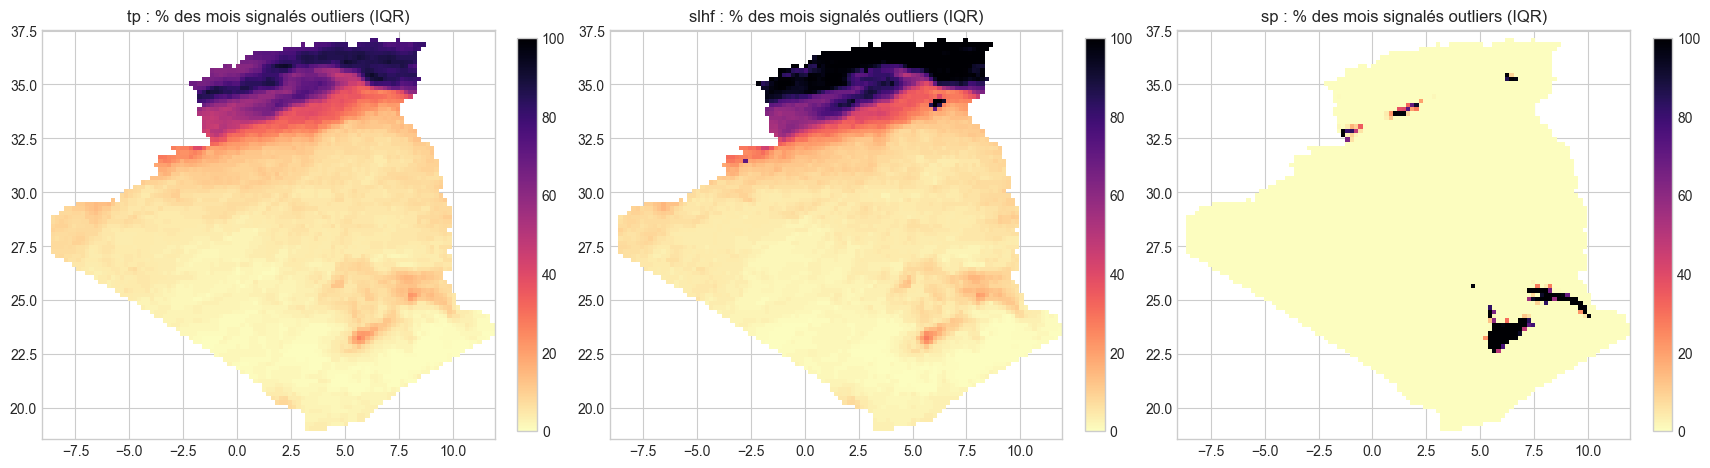

In [9]:
SKEWED = out_after.index[out_after["% IQR"] > 1].tolist()
north = LAT > 34                                   # Tell / littoral humide
rows = []
for v in SKEWED:
    a = ARR[v]; q1, q3 = np.percentile(a, [25, 75]); i = q3 - q1
    flag = (a < q1-1.5*i) | (a > q3+1.5*i)                     # (T, N)
    # cohérence spatiale : part des outliers dont au moins 2 cellules voisines (4-voisinage) sont aussi outliers le même mois
    g = np.zeros((T,) + vm.shape, bool); g[:, vm] = flag
    nb = np.zeros_like(g, dtype=int)
    nb[:, 1:, :] += g[:, :-1, :]; nb[:, :-1, :] += g[:, 1:, :]; nb[:, :, 1:] += g[:, :, :-1]; nb[:, :, :-1] += g[:, :, 1:]
    coherent = (nb[:, vm] >= 2)[flag].mean()
    rows.append({"variable": v, "% outliers IQR": 100*flag.mean(),
                 "% des outliers au nord (lat>34°)": 100*flag[:, north].sum()/flag.sum(),
                 "% des cellules au nord": 100*north.mean(),
                 "% outliers avec ≥2 voisines outliers": 100*coherent,
                 "% outliers dans des cellules outliers ≥ 50 % du temps": 100*flag[:, flag.mean(0) >= .5].sum()/flag.sum()})
loc = pd.DataFrame(rows).set_index("variable"); display(loc.round(1))

# Les plus forts extrêmes régionaux (hors période imputée) correspondent-ils à des épisodes datés ?
top = REG[["tp", "ro"]][clean].apply(lambda s: s.nlargest(3).index.strftime("%Y-%m").tolist())
print("Mois les plus pluvieux / plus fort ruissellement (moyenne régionale) :", top.to_dict(orient="list"))

fig, axes = plt.subplots(1, 3, figsize=(17, 5), constrained_layout=True)
for ax, v in zip(axes, ["tp", "slhf", "sp"]):
    a = ARR[v]; q1, q3 = np.percentile(a, [25, 75]); i = q3 - q1
    f = np.full(vm.shape, np.nan); f[vm] = 100*((a < q1-1.5*i) | (a > q3+1.5*i)).mean(0)
    im = ax.pcolormesh(conv.longitude, conv.latitude, f, cmap="magma_r", vmin=0, vmax=100); ax.set_aspect("equal")
    ax.set_title(f"{v} : % des mois signalés outliers (IQR)"); plt.colorbar(im, ax=ax, shrink=.8)
fig.savefig(FIG/"05_outliers_carte.png", dpi=110); plt.show()

**Décision** : les outliers sont des **régimes climatiques**, pas des erreurs :
- tp, slhf, e et ro : 58–63 % des outliers sont dans le Tell / littoral (lat > 34°), qui ne représente que 12 % des cellules ; 97–98 % ont au moins deux voisines outliers le même mois ;
- sp : 93 % des outliers sont dans des cellules signalées en permanence — Hoggar, Tassili, Atlas — c'est l'altitude ;
- les mois les plus extrêmes correspondent à des épisodes pluvieux datés (ex. 2024-09).

Supprimer ces valeurs effacerait tout le nord humide. Méthode retenue (cours 04, *transforming the data*) : **transformation** des variables à queue lourde, sans suppression. KNN et SVM (étape 2) sont sensibles aux queues lourdes ; Random Forest y est robuste.

skew                       % IQR                     
transformation aucune  log1p racine carrée aucune  log1p racine carrée
variable                                                              
e                4.12   2.86          2.29  16.16  15.58         13.12
ro              42.88  20.30          8.48  15.84  15.84         10.42
slhf             4.12   1.31          2.29  16.16   9.65         13.12
tp               5.63   3.26          2.42  14.52  13.78          8.51

log1p : skew(tp en mm/j) = 3.26 | skew(tp en mm/mois) = 1.36
racine carrée : skew(tp en mm/j) = 2.42 | skew(tp en mm/mois) = 2.42


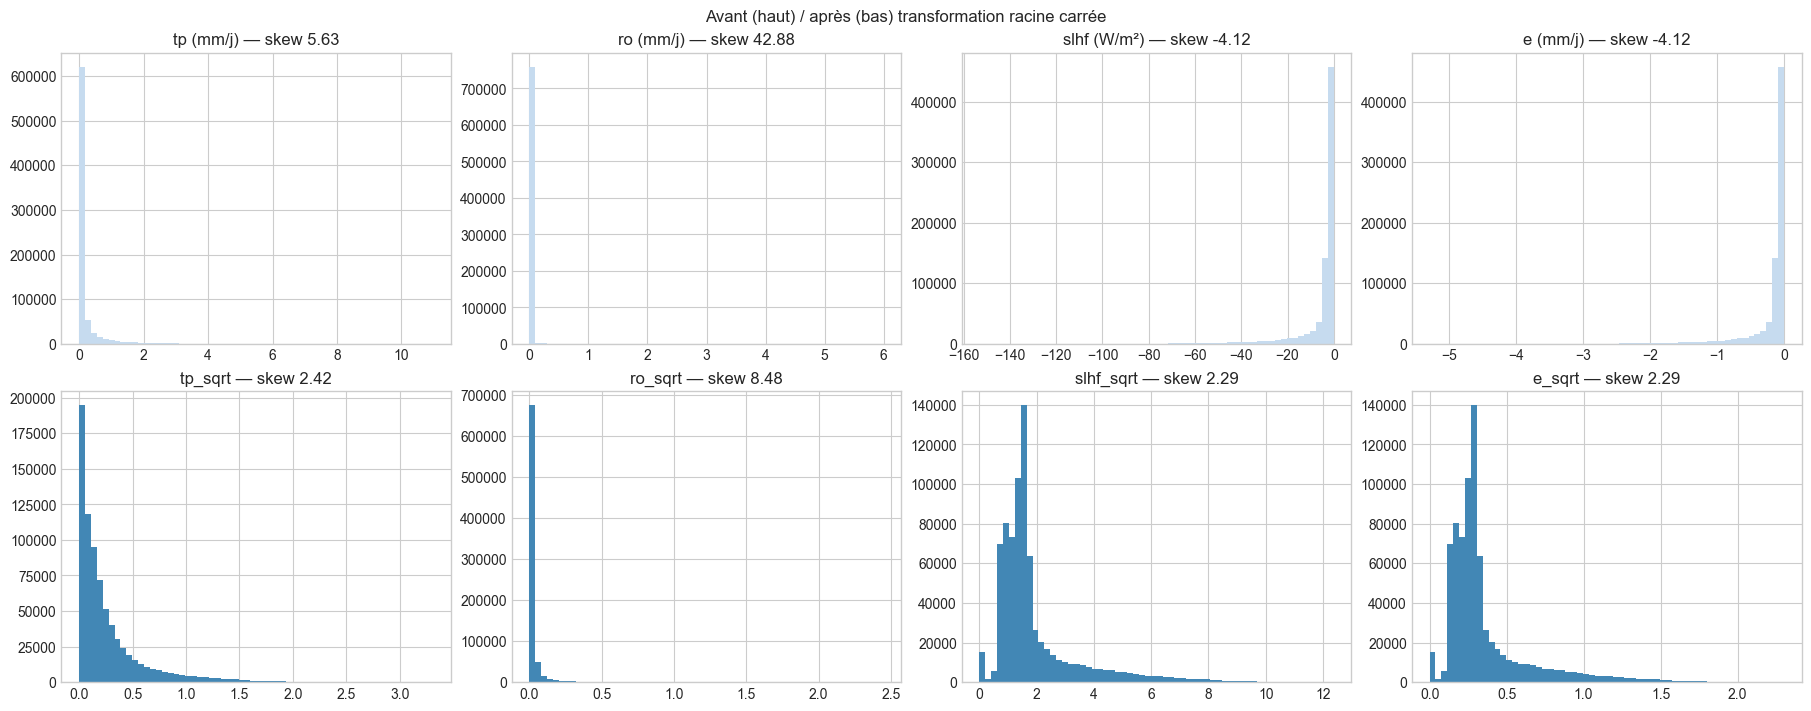

In [10]:
# Variables à queue lourde : tp, ro ≥ 0 ; slhf, e ≤ 0 (convention ERA5). On transforme la grandeur positive |x|.
HEAVY = ["tp", "ro", "slhf", "e"]
rows = []
for v in HEAVY:
    x = df[v].abs().values
    for name, f in [("aucune", lambda x: x), ("log1p", np.log1p), ("racine carrée", np.sqrt)]:
        y = f(x); q1, q3 = np.percentile(y, [25, 75]); i = q3 - q1
        rows.append({"variable": v, "transformation": name, "skew": stats.skew(y),
                     "% IQR": 100*((y < q1-1.5*i) | (y > q3+1.5*i)).mean()})
tr = pd.DataFrame(rows).pivot(index="variable", columns="transformation", values=["skew", "% IQR"])
display(tr.round(2))

# Contrôle de la dépendance à l'unité : même variable tp en mm/j et en mm/mois
for name, f in [("log1p", np.log1p), ("racine carrée", np.sqrt)]:
    print(f"{name} : skew(tp en mm/j) = {stats.skew(f(df.tp)):.2f} | skew(tp en mm/mois) = {stats.skew(f(df.tp*30.4)):.2f}")

# Transformation retenue : racine carrée de la grandeur positive (indépendante de l'unité)
TRANS = {v: f"{v}_sqrt" for v in HEAVY}
for v, c in TRANS.items():
    df[c] = np.sqrt(df[v].abs())          # slhf_sqrt, e_sqrt = racine de l'intensité du flux (|slhf|, |e|)
fig, axes = plt.subplots(2, 4, figsize=(18, 7), constrained_layout=True)
for k, (v, c) in enumerate(TRANS.items()):
    axes[0, k].hist(df[v], bins=60, color="#c6dbef"); axes[0, k].set_title(f"{v} ({UNITS[v]}) — skew {stats.skew(df[v]):.2f}")
    axes[1, k].hist(df[c], bins=60, color="#4287b5"); axes[1, k].set_title(f"{c} — skew {stats.skew(df[c]):.2f}")
fig.suptitle("Avant (haut) / après (bas) transformation racine carrée"); fig.savefig(FIG/"06_transformation_sqrt.png", dpi=110); plt.show()

**Choix de la transformation** : `log1p` dépend de l'unité (skew de tp : 3,26 en mm/j contre 1,36 en mm/mois) et traite différemment `e` et `slhf`, qui sont pourtant la même grandeur. La **racine carrée** est indépendante de l'unité et réduit le plus l'asymétrie de tp, ro et e : elle est retenue pour les 4 variables (sur |x| pour slhf et e, négatives par convention ERA5).

**Ce que la transformation ne règle pas** : une asymétrie résiduelle (skew ≈ 2,3–2,4 pour tp, slhf) subsiste, car les distributions mélangent deux régimes (nord humide / Sahara sec). C'est une propriété réelle des données, pas un défaut à supprimer.

## Étape 5 — Faible variabilité

Le seuil du cours (variance < 0,01) dépend des unités : la variance de ro vaut 1,5·10⁻³ en mm/j mais 1,5·10⁻⁹ en m/j. On l'applique donc **après normalisation Min-Max** (cours 05) et sur la représentation retenue à l'étape 4. On ajoute la part de la valeur la plus fréquente et la part de variance **temporelle** (dimension propre au dataset).

In [11]:
SI = {"ro": 1e-3, "e": 1e-3, "tp": 1e-3}                 # mm/j -> m/j, pour montrer l'effet de l'unité
def mm_var(x): return ((x - x.min()) / (x.max() - x.min())).var()
REPR = {v: TRANS.get(v, v) for v in BASE}                 # représentation après transformation
rows = []
for v in BASE:
    x = df[v].values; xt = df[REPR[v]].values
    a = ARR[v]
    rows.append({"variable": v, "var (unités d'analyse)": x.var(), "var (unités SI du fichier)": (x*SI.get(v, 1)).var() if v in SI else np.nan,
                 "var Min-Max (brut corrigé)": mm_var(x), f"var Min-Max (représentation retenue)": mm_var(xt),
                 "% valeur la plus fréquente": 100*pd.Series(np.round(x, 6)).value_counts(normalize=True).iloc[0],
                 "% de variance temporelle": 100*a.var(axis=0).mean()/a.var()})
VAR = pd.DataFrame(rows).set_index("variable")
print(VAR.to_string(float_format=lambda x: f"{x:.3g}"))
LOW = VAR.index[VAR["var Min-Max (représentation retenue)"] < 0.01].tolist()
print("Variance Min-Max < 0.01 sur la représentation retenue :", LOW)
print("Variance Min-Max < 0.01 sans transformation (brut corrigé) :", VAR.index[VAR["var Min-Max (brut corrigé)"] < 0.01].tolist())
q = df["ro"].quantile([.5, .75, .9, .99]); print("Quantiles de ro (mm/j) :", q.round(4).to_dict(), "| % ro < 0.01 mm/j :", round(100*(df.ro < 0.01).mean(), 1))

          var (unités d'analyse)  var (unités SI du fichier)  var Min-Max (brut corrigé)  var Min-Max (représentation retenue)  % valeur la plus fréquente  % de variance temporelle
variable                                                                                                                                                                            
d2m                         23.4                         NaN                      0.0145                                0.0145                     0.00458                      66.3
t2m                         76.6                         NaN                      0.0473                                0.0473                     0.00262                      84.9
slhf                         141                         NaN                     0.00601                                0.0152                        1.95                      29.5
ssr                     1.78e+03                         NaN                      0.0294       

**Lecture** :
- Sans transformation, 5 variables passent sous le seuil (slhf, sshf, ro, e, tp) : un artefact des queues lourdes, d'où l'ordre choisi.
- **ro** : variance Min-Max 0,00056 même après transformation (≈ 18 fois sous le seuil) et 95,9 % des valeurs < 0,01 mm/j : variable réellement quasi constante → **candidate à l'élimination**.
- **sshf** : 0,0098, juste au seuil, uniquement à cause de quelques valeurs extrêmes qui étirent l'étendue ; 76 % de variance temporelle et forte relation avec la cible → **conservée**.
- **sp** : seulement 1 % de variance temporelle, elle ne change presque pas dans le temps. Elle porte l'**altitude** de la cellule (information spatiale), liée à la température → **conservée**.

## Étape 6 — Corrélations et redondance

**Formule** : aucune variable n'est normale (test de l'EDA), donc **Spearman** (cours 03). Il est invariant aux transformations monotones : les décisions ne dépendent pas de la racine carrée. Pour départager deux variables redondantes, on utilise leur corrélation avec la cible t2m(t+1) (filtre par corrélation, cours 05).

Paires |ρ Spearman| > 0.90 — données BRUTES : {('slhf_sqrt', 'e_sqrt'): 1.0, ('ro_sqrt', 'tp_sqrt'): 0.98, ('ssr', 'sshf'): -0.948}
Paires |ρ Spearman| > 0.90 — données CORRIGÉES : {('slhf_sqrt', 'e_sqrt'): 1.0, ('ro_sqrt', 'tp_sqrt'): 0.969, ('ssr', 'sshf'): -0.954}


,d2m,slhf_sqrt,ssr,str,sshf,ro_sqrt,e_sqrt,u10,v10,sp,tp_sqrt
ρ avec t2m(t+1),0.112,0.144,0.814,-0.853,-0.722,-0.178,0.144,-0.204,0.059,0.066,-0.181


ρ Spearman entre sp moyen et t2m moyen des cellules : 0.37


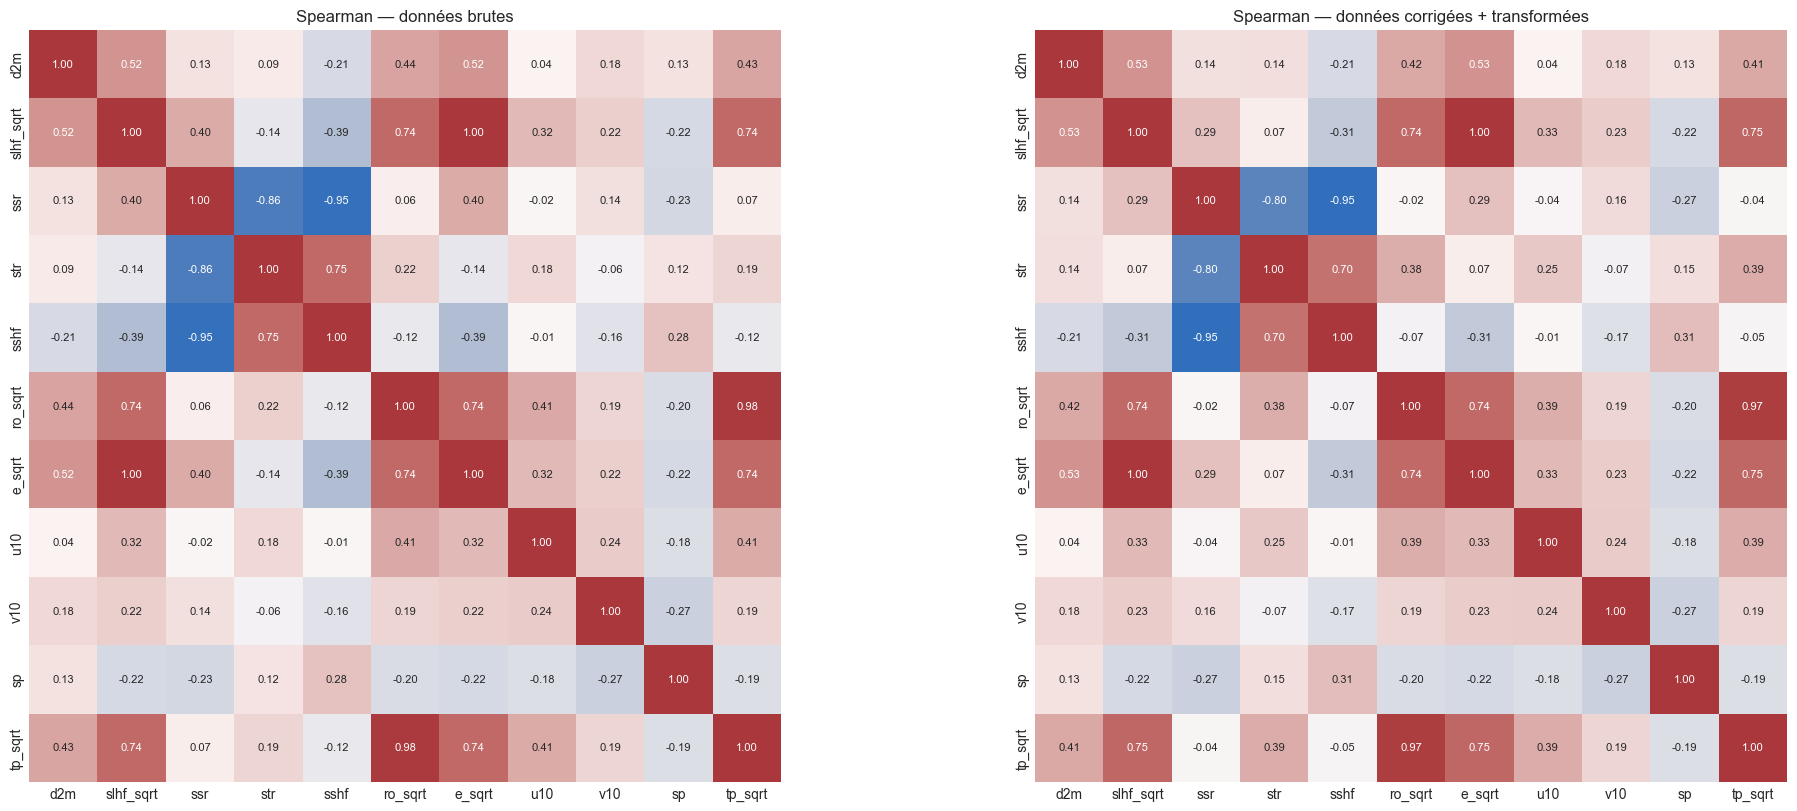

In [12]:
# Cible : t2m du mois suivant, même cellule (nécessaire pour départager les paires redondantes)
A = ARR["t2m"]
df["t2m_next"] = np.vstack([A[1:], np.full((1, N), np.nan)]).reshape(-1)

CAND = [REPR[v] for v in BASE if v != "t2m"]            # les 11 variables du sujet, représentation retenue
S = df.sample(150_000, random_state=42)                 # Spearman sur 150 000 lignes (rangs, coût n log n)
rk = S[CAND + ["t2m", "t2m_next"]].rank()
sp_after = rk[CAND].corr()
Sb = df_raw.sample(150_000, random_state=42)
Sb = pd.DataFrame({REPR[v]: (np.sqrt(Sb[v].abs()) if v in TRANS else Sb[v]) for v in BASE if v != "t2m"})   # même représentation
sp_before = Sb[CAND].rank().corr()

def high_pairs(m, thr=0.90):
    p = m.where(np.triu(np.ones(m.shape, bool), 1)).stack()
    return p[p.abs() > thr].sort_values(key=abs, ascending=False)
print("Paires |ρ Spearman| > 0.90 — données BRUTES :", high_pairs(sp_before).round(3).to_dict())
print("Paires |ρ Spearman| > 0.90 — données CORRIGÉES :", high_pairs(sp_after).round(3).to_dict())

target_corr = rk[CAND].corrwith(rk["t2m_next"]).rename("ρ avec t2m(t+1)")
display(target_corr.round(3).to_frame().T)

# sp et altitude : une variable presque constante dans le temps peut rester discriminante dans l'espace
cell_sp, cell_t = ARR["sp"].mean(0), ARR["t2m"].mean(0)
print(f"ρ Spearman entre sp moyen et t2m moyen des cellules : {stats.spearmanr(cell_sp, cell_t)[0]:.2f}")

fig, axes = plt.subplots(1, 2, figsize=(20, 8), constrained_layout=True)
for ax, m, t in [(axes[0], sp_before, "brutes"), (axes[1], sp_after, "corrigées + transformées")]:
    sns.heatmap(m, annot=True, fmt=".2f", cmap="vlag", center=0, vmin=-1, vmax=1, square=True, cbar=False, ax=ax, annot_kws={"size": 8})
    ax.set_title(f"Spearman — données {t}")
fig.savefig(FIG/"07_correlations_avant_apres.png", dpi=110); plt.show()

**Lecture** : les trois paires de l'EDA sont confirmées sur données corrigées (slhf–e 1,00 ; ro–tp 0,97 ; ssr–sshf −0,95). Le lien ro–tp est conservé grâce au choix de la régression à l'étape 2 : la validation y montrait qu'une imputation de ro par climatologie l'aurait cassé (ρ = 0,55 au lieu de 0,98 sur les blocs de validation).

In [13]:
# Paire ssr – sshf : sshf apporte-t-elle une information propre ? (résidu de sshf après régression linéaire sur ssr)
lr = LinearRegression().fit(S[["ssr"]], S["sshf"]); resid_sshf = S["sshf"] - lr.predict(S[["ssr"]])
ok = S["t2m_next"].notna()
print(f"ssr–sshf : R² = {lr.score(S[['ssr']], S['sshf']):.3f} ; ρ(résidu de sshf, t2m(t+1)) = {stats.spearmanr(resid_sshf[ok], S.t2m_next[ok])[0]:.3f}")
lr2 = LinearRegression().fit(S[["tp_sqrt"]], S["ro_sqrt"]); resid_ro = S["ro_sqrt"] - lr2.predict(S[["tp_sqrt"]])
print(f"tp–ro   : R² = {lr2.score(S[['tp_sqrt']], S['ro_sqrt']):.3f} ; ρ(résidu de ro, t2m(t+1)) = {stats.spearmanr(resid_ro[ok], S.t2m_next[ok])[0]:.3f}")

DROP = {
 "e":   f"copie exacte de slhf (e = slhf / {K_E:.3f}, ρ = 1.00) : aucune information perdue",
 "ro":  f"variance Min-Max {VAR.loc['ro','var Min-Max (représentation retenue)']:.5f} < 0.01 même après transformation, "
        f"{100*(df.ro < 0.01).mean():.1f} % des valeurs < 0.01 mm/j, et redondante avec tp (ρ = {sp_after.loc['ro_sqrt','tp_sqrt']:.2f})",
}
KEEP_NOTE = {
 "sshf": f"corrélée à ssr (ρ = {sp_after.loc['ssr','sshf']:.2f}) mais son résidu reste lié à la cible : information propre (répartition de l'énergie en surface) ; "
         "variance Min-Max juste sous le seuil à cause de quelques valeurs extrêmes, 76 % de variance temporelle → conservée",
 "sp":   "quasi constante dans le temps (1 % de variance temporelle) mais porte l'altitude de la cellule (information spatiale) → conservée",
}
display(pd.Series(DROP, name="variable éliminée — raison").to_frame())
display(pd.Series(KEEP_NOTE, name="variable signalée mais conservée — raison").to_frame())
FEATURES_VARS = [REPR[v] for v in BASE if v not in ("t2m", *DROP)]
print("Variables climatiques retenues :", FEATURES_VARS)
rk2 = sp_after.loc[FEATURES_VARS, FEATURES_VARS].values.copy(); np.fill_diagonal(rk2, 0)
print(f"|ρ| max entre variables retenues : {np.abs(rk2).max():.3f} (ssr–sshf, conservée volontairement)")

ssr–sshf : R² = 0.885 ; ρ(résidu de sshf, t2m(t+1)) = 0.354
tp–ro   : R² = 0.547 ; ρ(résidu de ro, t2m(t+1)) = 0.092


,variable éliminée — raison
e,"copie exacte de slhf (e = slhf / 28.944, ρ = 1..."
ro,variance Min-Max 0.00056 < 0.01 même après tra...


,variable signalée mais conservée — raison
sshf,corrélée à ssr (ρ = -0.95) mais son résidu res...
sp,quasi constante dans le temps (1 % de variance...


Variables climatiques retenues : ['d2m', 'slhf_sqrt', 'ssr', 'str', 'sshf', 'u10', 'v10', 'sp', 'tp_sqrt']
|ρ| max entre variables retenues : 0.954 (ssr–sshf, conservée volontairement)


**Décisions** :
- **e éliminée** : copie exacte de slhf, aucune perte d'information.
- **ro éliminée** : très faible variabilité (étape 5) et redondante avec tp (ρ = 0,97 ; son résidu après tp n'est presque plus lié à la cible, ρ = 0,09).
- **ssr et sshf conservées toutes les deux**, malgré ρ = −0,95 : la relation est physique (le flux de chaleur sensible est alimenté par l'énergie solaire absorbée), mais la partie de sshf non expliquée par ssr reste liée à la cible (ρ = 0,35). Elle décrit la répartition de l'énergie en surface (sol sec / humide). Le risque d'instabilité cité par le cours concerne surtout la régression ; les modèles du projet (KNN, SVM, RF) y sont peu sensibles. On peut retester ce choix à l'étape 2 (importance RF, ou RFE).

**Remarque** : le sujet liste `Runoff` et `Total evaporation` parmi les features. Leur élimination est une décision de preprocessing justifiée ci-dessus ; si l'enseignante exige les 11 variables, il suffit de rajouter `e_sqrt` (identique à slhf_sqrt) et `ro_sqrt`, présentes dans `df`.

## Étape 7 — Dataset final

Cible : classe de t2m du mois suivant (même cellule), 3 intervalles de même largeur. Variables explicatives : variables du sujet retenues + mois + année (consigne). `t2m` du mois courant est gardée comme colonne (nécessaire au clustering) mais ne figure pas dans la liste des features du sujet.

In [14]:
# Cible : classe de t2m(t+1) en 3 intervalles de même largeur (consigne du projet)
EDGES = np.linspace(df["t2m_next"].min(), df["t2m_next"].max(), 4)
df["classe"] = pd.cut(df["t2m_next"], bins=EDGES, labels=["Froid", "Modéré", "Chaud"], include_lowest=True)
df["prelim_era5t"] = np.repeat(np.isin(times.strftime("%Y-%m"), expver[expver == "0005"].index), N)
print("Seuils des classes (°C) :", np.round(EDGES, 2))

FEATURES = FEATURES_VARS + ["month", "year"]                      # variables du sujet retenues + mois + année
META = ["time", "cell", "lat", "lon", "n_sub", "imputed_accum", "prelim_era5t", "t2m", "t2m_next"]   # t2m conservée pour le clustering
final = df.dropna(subset=["t2m_next"])[META + FEATURES + ["classe"]].reset_index(drop=True)
assert final[FEATURES].isna().sum().sum() == 0 and not final.duplicated(["cell", "time"]).any()
print(f"Dataset final : {final.shape[0]:,} lignes × {final.shape[1]} colonnes | {len(FEATURES)} variables explicatives : {FEATURES}")
print(f"Période des variables : {final.time.min():%Y-%m} → {final.time.max():%Y-%m} (le dernier mois, sans mois suivant, est retiré)")
print("Répartition des classes (%) :", (final["classe"].value_counts(normalize=True)*100).round(1).to_dict())
print(f"Lignes imputées (2022-09→2024-02) : {final.imputed_accum.mean()*100:.1f} % | cellules incomplètes : {(final.n_sub < 4).mean()*100:.2f} % | "
      f"lignes ERA5T préliminaires : {final.prelim_era5t.mean()*100:.2f} %")
final.to_parquet(OUT/"dataset_clean.parquet")
check = pd.read_parquet(OUT/"dataset_clean.parquet")
print("Relu depuis le disque :", check.shape, "| identique :", check.equals(final))

Seuils des classes (°C) : [ 0.91 14.33 27.74 41.16]
Dataset final : 759,360 lignes × 21 colonnes | 11 variables explicatives : ['d2m', 'slhf_sqrt', 'ssr', 'str', 'sshf', 'u10', 'v10', 'sp', 'tp_sqrt', 'month', 'year']
Période des variables : 2015-01 → 2026-08 (le dernier mois, sans mois suivant, est retiré)
Répartition des classes (%) : {'Modéré': 43.1, 'Chaud': 39.8, 'Froid': 17.0}
Lignes imputées (2022-09→2024-02) : 12.9 % | cellules incomplètes : 4.15 % | lignes ERA5T préliminaires : 0.71 %
Relu depuis le disque : (759360, 21) | identique : True


## Validation globale avant / après

On réapplique les critères de l'EDA aux données brutes et au dataset final.

Périodes incohérentes AVANT : [('ssr', '2022-09', '2024-02', 18), ('str', '2022-09', '2024-02', 18), ('sshf', '2022-09', '2024-02', 18)]
Périodes incohérentes APRÈS : aucune
Écart à la climatologie dans la période / écart habituel (1 = variabilité normale) :


,slhf,ssr,str,sshf,ro,e,tp
AVANT,2.29,29.73,17.82,16.61,1.10,2.29,1.45
APRÈS,1.23,0.83,1.08,0.92,0.64,1.23,1.06


,dans le dataset final,skew avant,skew après,% IQR avant,% IQR après,var Min-Max avant,var Min-Max après
variable,,,,,,,
d2m,d2m,0.292,0.299,1.146,1.203,0.015,0.014
slhf,slhf_sqrt,-4.211,2.290,16.464,13.192,0.006,0.015
ssr,ssr,-0.207,-0.121,0.000,0.000,0.033,0.030
str,str,0.583,0.363,0.038,0.087,0.042,0.029
sshf,sshf,-0.447,-0.377,0.763,0.919,0.010,0.010
ro,éliminée (faible variabilité),45.175,NaN,16.232,NaN,0.000,NaN
e,éliminée (doublon de slhf),-4.212,NaN,16.464,NaN,0.006,NaN
u10,u10,0.075,0.069,0.713,0.721,0.013,0.013
v10,v10,-0.239,-0.242,1.076,1.065,0.016,0.016


Paires |ρ| > 0.90 dans le dataset final : {('ssr', 'sshf'): -0.955}
Classes brut vs final (%) : {'Modéré': 43.1, 'Chaud': 39.8, 'Froid': 17.0} | {'Modéré': 43.1, 'Chaud': 39.8, 'Froid': 17.0}
Dimensions : brut 764,784 × 12 variables → final 759,360 × 11 variables explicatives (lignes retirées : 5,424 = dernier mois sans cible) | NaN : 0 → 0


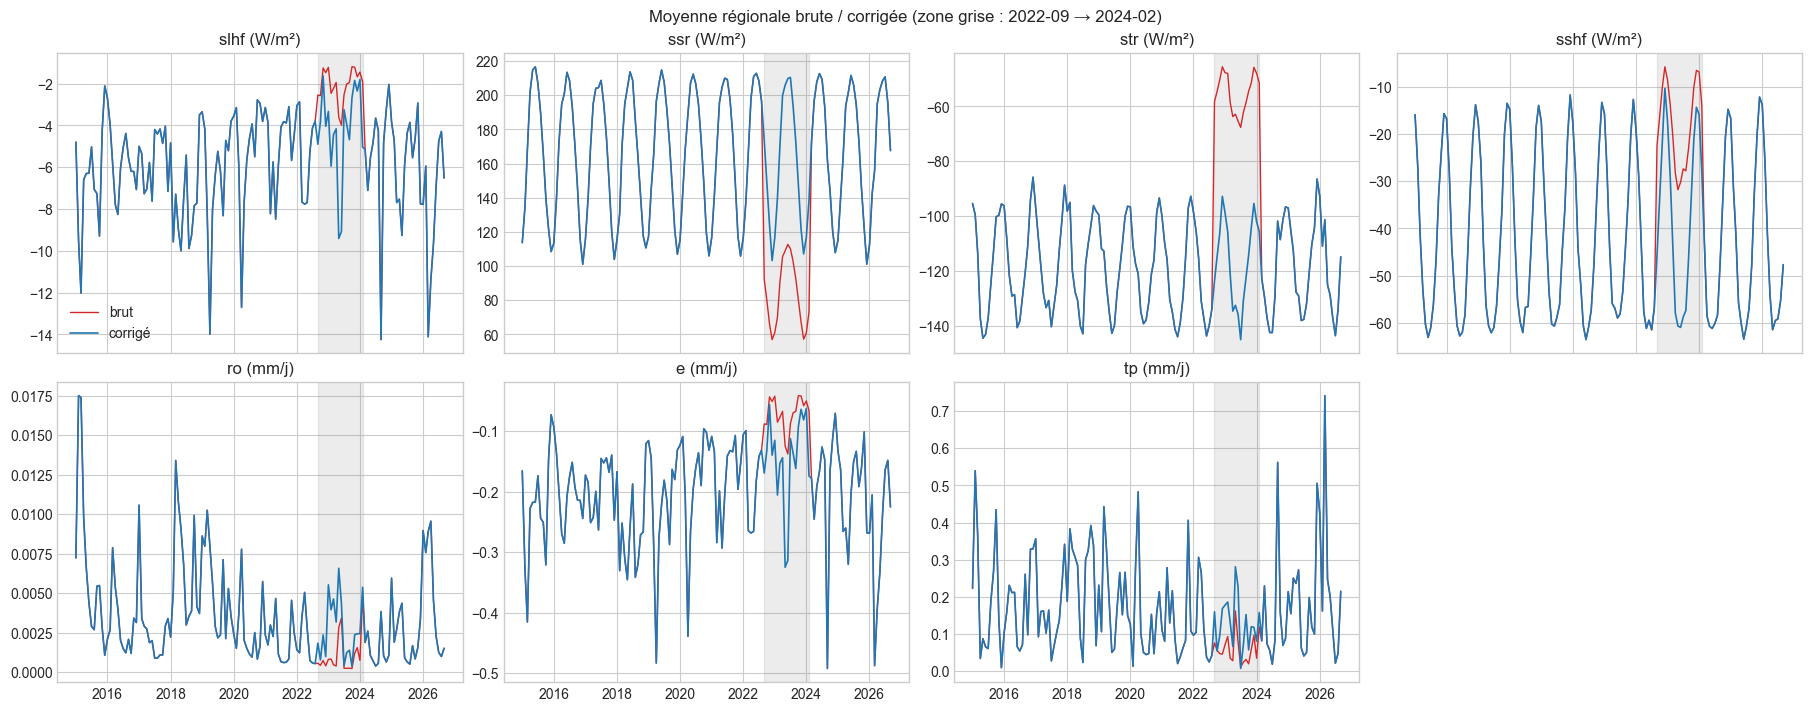

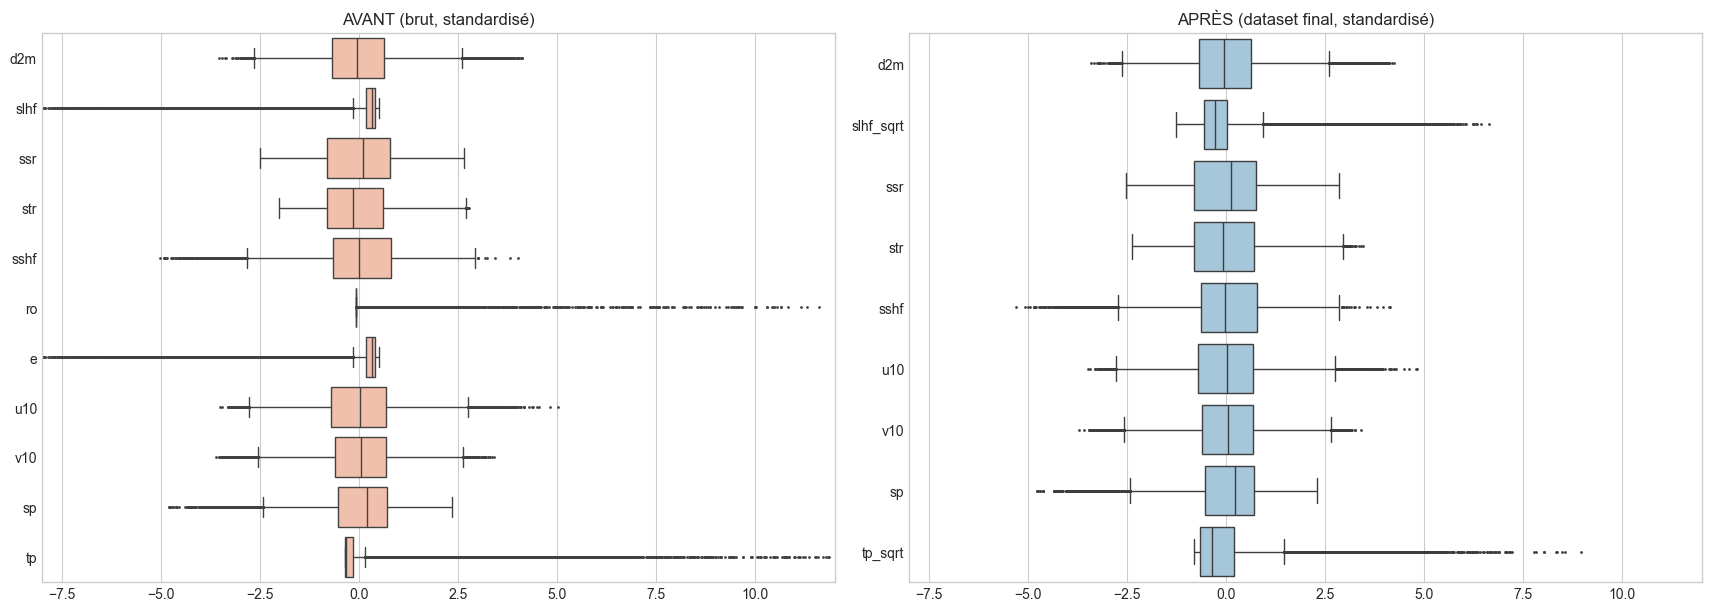

In [15]:
# 1) Détecteur de l'EDA (z robuste par mois calendaire, |z| > 3.5 pendant ≥ 3 mois consécutifs) appliqué avant et après
def persistent_anomalies(reg, cols):
    rz = reg[cols].groupby(reg.index.month).transform(lambda s: (s - s.median()) / (1.4826*(s - s.median()).abs().median()))
    out = []
    for v in cols:
        f = rz[v].abs() > 3.5; g = (f != f.shift()).cumsum()
        for _, run in f.groupby(g):
            if run.iloc[0] and len(run) >= 3: out.append((v, run.index[0].strftime("%Y-%m"), run.index[-1].strftime("%Y-%m"), len(run)))
    return out
print("Périodes incohérentes AVANT :", persistent_anomalies(REG_RAW, BASE))
print("Périodes incohérentes APRÈS :", persistent_anomalies(REG, BASE) or "aucune")

# 2) Écart moyen des 18 mois à la climatologie des mois sains, en écarts-types (la référence = variabilité naturelle)
def window_gap(reg):
    cl = reg[clean].groupby(times[clean].month).median()
    r = reg - cl.loc[times.month].values
    return (r[win].abs().mean() / r[clean].abs().mean())
gap = pd.DataFrame({"AVANT": window_gap(REG_RAW[ACCUM]), "APRÈS": window_gap(REG[ACCUM])}).T
print("Écart à la climatologie dans la période / écart habituel (1 = variabilité normale) :"); display(gap.round(2))

# 3) Tableau comparatif des variables du sujet (brut → final)
SUBJ = [v for v in BASE if v != "t2m"]
rows = []
for v in SUBJ:
    xb = df_raw[v].values; xa = final[REPR[v]].values if REPR[v] in final else None
    def iqr(x): q1, q3 = np.percentile(x, [25, 75]); i = q3 - q1; return 100*((x < q1-1.5*i) | (x > q3+1.5*i)).mean()
    rows.append({"variable": v, "dans le dataset final": REPR[v] if xa is not None else f"éliminée ({'doublon de slhf' if v == 'e' else 'faible variabilité'})",
                 "skew avant": stats.skew(xb), "skew après": stats.skew(xa) if xa is not None else np.nan,
                 "% IQR avant": iqr(xb), "% IQR après": iqr(xa) if xa is not None else np.nan,
                 "var Min-Max avant": mm_var(xb), "var Min-Max après": mm_var(xa) if xa is not None else np.nan})
SUMMARY = pd.DataFrame(rows).set_index("variable"); display(SUMMARY.round(3))

# 4) Corrélations finales et bilan global
fin_rho = final.sample(150_000, random_state=1)[FEATURES_VARS].rank().corr()
m = fin_rho.values.copy(); np.fill_diagonal(m, 0)
print(f"Paires |ρ| > 0.90 dans le dataset final : {high_pairs(fin_rho).round(3).to_dict()}")
cls_raw = pd.cut(df_raw.groupby('cell')['t2m'].shift(-1), bins=EDGES, labels=["Froid","Modéré","Chaud"], include_lowest=True)
print("Classes brut vs final (%) :", (cls_raw.value_counts(normalize=True)*100).round(1).to_dict(), "|", (final.classe.value_counts(normalize=True)*100).round(1).to_dict())
print(f"Dimensions : brut {len(df_raw):,} × {len(BASE)} variables → final {final.shape[0]:,} × {len(FEATURES)} variables explicatives "
      f"(lignes retirées : {len(df_raw)-len(final):,} = dernier mois sans cible) | NaN : {int(df_raw[BASE].isna().sum().sum())} → {int(final.isna().sum().sum())}")

# Figures du rapport : séries régionales et boxplots standardisés avant/après
fig, axes = plt.subplots(2, 4, figsize=(18, 7), constrained_layout=True, sharex=True)
for ax, v in zip(axes.flat, ACCUM):
    ax.plot(times, REG_RAW[v], color="tab:red", lw=1, label="brut"); ax.plot(times, REG[v], color="tab:blue", lw=1.2, label="corrigé")
    ax.axvspan(ANOM_START, ANOM_END, color="grey", alpha=.15); ax.set_title(f"{v} ({UNITS[v]})")
axes.flat[0].legend(); axes.flat[-1].set_visible(False)
fig.suptitle("Moyenne régionale brute / corrigée (zone grise : 2022-09 → 2024-02)"); fig.savefig(FIG/"08_series_avant_apres.png", dpi=110); plt.show()

fig, axes = plt.subplots(1, 2, figsize=(17, 6), constrained_layout=True)
zb = df_raw[SUBJ].sample(60_000, random_state=0); zb = (zb - zb.mean()) / zb.std()
za = final[FEATURES_VARS].sample(60_000, random_state=0); za = (za - za.mean()) / za.std()
sns.boxplot(data=zb, orient="h", ax=axes[0], color="#fcbba1", fliersize=1); axes[0].set_title("AVANT (brut, standardisé)")
sns.boxplot(data=za, orient="h", ax=axes[1], color="#9ecae1", fliersize=1); axes[1].set_title("APRÈS (dataset final, standardisé)")
for a in axes: a.set_xlim(-8, 12)
fig.savefig(FIG/"09_boxplots_avant_apres.png", dpi=110); plt.show()

## Bilan

| Constat | Résultat de la vérification | Traitement | Effet vérifié |
|---|---|---|---|
| Incohérence 2022–2024 | 18 mois, **7 variables accumulées** ≈ ÷2 (bug connu ERA5-Land) | Valeurs → manquantes, puis régression linéaire par cellule (validée sur 2 blocs sains) ; e = slhf/28,944 | Plus aucune période détectée ; écart à la climatologie des rayonnements (ssr, str, sshf) 17–30 → 0,8–1,1 |
| Manquants frontière nord | 12 points de mer bruts ; 22 cellules NaN selon l'intersection ; 225 cellules incomplètes (4,15 %) | Pas d'imputation de la mer ; cellules incomplètes conservées (moyenne des sous-cellules), drapeau `n_sub` | 0 NaN |
| Outliers / asymétrie | ~15 % IQR pour tp, slhf, e, ro : régimes du nord humide et de l'altitude, spatialement cohérents | Aucune suppression ; racine carrée | skew tp 5,8 → 2,4, slhf −4,2 → 2,3 ; % IQR tp 15 → 8,6 |
| Faible variabilité | Seul ro est réellement quasi constant (seuil appliqué après Min-Max et transformation) | ro éliminée ; sp et sshf conservées (justifié) | Toutes les variables retenues ≥ 0,0098 |
| Corrélations (Spearman) | slhf–e 1,00 ; ro–tp 0,97 ; ssr–sshf −0,95 | e éliminée (doublon) ; ssr et sshf conservées (information propre de sshf) | 1 seule paire > 0,90, gardée volontairement |

**Limites** : les 18 mois imputés sont des estimations (vérifiables seulement en re-téléchargeant le produit « by hour of day 00:00 ») ; leur variabilité est un peu atténuée (écart relatif 0,64–1,23). Les mois 2026-08 et 2026-09 sont préliminaires (ERA5T). Le scaling et le découpage chronologique train/test restent à faire dans l'étape 2.